\# Платформа FishGrow: исследовательский анализ данных

> *Дисциплина:* Введение в искусственный интеллект  
> *Студент:* Силкин Илья Алексеевич
> *Группа:* 22206
> *Ветка Git:* lab/01-eda  
> *Исходный репозиторий:* https://github.com/tylerrussin/Fish-Dimensions-Regression-Analysis  
> *Python:* 3.10.11  
> *Ключевые библиотеки:* pandas 3.0.5, numpy 2.5.3, matplotlib 3.11.2, seaborn 0.13.2, statsmodels, scikit-learn

## 1. Постановка задачи

- *Целевая переменная:* `Weight` — масса рыбы в граммах.
- *Признаки:* пять геометрических измерений (см) и категория вида.
- *Задача:* понять схему данных, диапазоны значений, ошибки измерения, представленность видов и возможные утечки до построения модели.
- Тестовая выборка остаётся закрытой до финальной проверки модели.

## 2. Паспорт данных

### 2.1 Общие сведения
- *Источник:* `assets/data/Fish.csv` (в исходном репозитории) → скопирован в `data/fish.csv`
- *Размер:* 159 строк × 7 столбцов
- *Единица наблюдения:* одна особь рыбы
- *Пропуски:* отсутствуют
- *Дубликаты:* 0 полных, 1 по измерениям (без `Weight`)

### 2.2 Паспорт полей

| Поле | Тип | Единицы | Назначение | Допустимый диапазон | Проверки |
| :--- | :--- | :--- | :--- | :--- | :--- |
| `Species` | категория | — | признак (группирующий) | 7 значений: Bream, Parkki, Perch, Pike, Roach, Smelt, Whitefish | Нет пустых строк, нет дублей написаний |
| `Weight` | float | граммы | целевая переменная | > 0, до ~1700 г | Положительность; найдена ошибка — `Weight = 0` |
| `Length1` | float | см | признак (вертикальная длина) | > 0 | Положительность; согласованность с L2, L3 |
| `Length2` | float | см | признак (диагональная длина) | > 0 | Согласованность: обычно L1 ≤ L2 |
| `Length3` | float | см | признак (поперечная длина) | > 0 | Согласованность: обычно L2 ≤ L3 |
| `Height` | float | см | признак (высота) | > 0 | Положительность |
| `Width` | float | см | признак (ширина) | > 0 | Положительность |

### 2.3 Подтверждённые факты
- *Единицы измерения (г, см)* взяты из кода приложения: `pages/index.py`, `pages/predictions.py` — подписи `"Fish Weight (grams)"`, `"Fish Cross Length (cm)"`.

### 2.4 Риски данных
- Одна строка с `Weight = 0` — физически невозможно; ошибка ввода.
- Три строки с аномально большой массой (Pike, 1550–1650 г) — реальные крупные особи, не ошибка.
- Виды сильно несбалансированы (Whitefish — 6 экз., Smelt — 14 экз.) — может повлиять на обучение модели.

### 3.3. Автоматическая проверка качества

Реализован модуль `src/data_checks.py`, содержащий функции проверок. Все проверки вызываются одной функцией `run_all_checks(df)` и покрывают шесть групп требований задания:

| Группа | Функция | Что проверяет |
| :--- | :--- | :--- |
| Форма, типы, дубликаты | `check_shape_and_dtypes`, `check_duplicates` | размер, dtype, полные и почти-дубликаты |
| Пропуски, бесконечности, невозможные значения | `check_missing_and_inf`, `check_non_positive` | NaN, ±inf, неположительные длины и массы |
| Согласованность геометрии | `check_length_consistency`, `check_impossible_combos` | отношение трёх длин, Width > Height, Height > Length3 |
| Редкие категории и дисбаланс видов | `check_category_balance`, `check_category_spelling` | частоты категорий, дубликаты написаний |
| Почти одинаковые строки | `check_near_duplicates` | повторы после округления |
| Уникальные поля и утечки | `check_unique_fields`, `check_leak_candidates` | потенциальные идентификаторы, поля с корреляцией > 0.98 |

In [52]:
# 1. Импорт модуля
# Импорт библиотек
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Путь к данным (мы внутри папки notebooks, поэтому ../ = выйти на уровень выше)
DATA_PATH = '../assets/data/Fish.csv'

# Загрузка данных
df = pd.read_csv(DATA_PATH)

# Вывод первых 5 строк для проверки
df.head()
import sys
from pathlib import Path
sys.path.append(str(Path("..").resolve()))

from src.data_checks import run_all_checks, summary

# 2. Запуск проверок
results = run_all_checks(df)

print("Форма:", results["shape"])
print("Столбцы:", results["columns"])

Форма: (159, 7)
Столбцы: ['Species', 'Weight', 'Length1', 'Length2', 'Length3', 'Height', 'Width']


In [53]:
# 3. Сводка одной таблицей
summary(results)

,Проверка,Значение,Статус
0,Форма таблицы,159 x 7,OK
1,Полные дубликаты,0,OK
2,Почти-дубликаты,0,OK
3,Неположительные значения,1,⚠️
4,Невозможные комбинации,0,OK
5,Согласованность длин,0,OK
6,Уникальные поля,0,OK
7,Кандидаты на утечку,0,OK


In [54]:
print("=== 1. Форма, типы, пропуски ===")
print(results["quality"])
print("\nДубликаты:", results["duplicates"])

=== 1. Форма, типы, пропуски ===
           dtype  missing  miss_%  unique
Species   object        0     0.0       7
Weight   float64        0     0.0     101
Length1  float64        0     0.0     116
Length2  float64        0     0.0      93
Length3  float64        0     0.0     124
Height   float64        0     0.0     154
Width    float64        0     0.0     152

Дубликаты: {'full_duplicates': 0, 'near_duplicates_rounded': 0}


In [55]:
print("\n=== 2. Пропуски и бесконечности ===")
print("Пропуски:", df.isna().sum().sum())
numeric_cols = df.select_dtypes(include=np.number).columns
print("Бесконечности:", np.isinf(df[numeric_cols]).sum().sum())

# --- Неположительные значения ---
print("\n=== Неположительные значения ===")
size_cols = ['Length1', 'Length2', 'Length3', 'Height', 'Width']
for col in ['Weight'] + size_cols:
    count = int((df[col] <= 0).sum())
    if count:
        print(f"  {col}: {count} шт., строки {df[df[col] <= 0].index.tolist()}")
    else:
        print(f"  {col}: OK")

# --- Невозможные комбинации ---
print("\n=== Невозможные комбинации ===")
mask_width = df['Width'] > df['Height']
print(f"  Width > Height: {mask_width.sum()} строк")
mask_height = df['Height'] > df['Length3']
print(f"  Height > Length3: {mask_height.sum()} строк")



=== 2. Пропуски и бесконечности ===
Пропуски: 0
Бесконечности: 0

=== Неположительные значения ===
  Weight: 1 шт., строки [40]
  Length1: OK
  Length2: OK
  Length3: OK
  Height: OK
  Width: OK

=== Невозможные комбинации ===
  Width > Height: 0 строк
  Height > Length3: 0 строк


In [56]:
print("=== 3. Согласованность длин ===")
ld = results["length_issue"]
if ld.empty:
    print("  Подозрительных строк нет")
else:
    print(ld)

=== 3. Согласованность длин ===
  Подозрительных строк нет


In [57]:
print("\n=== 4. Баланс категорий ===")
counts = df['Species'].value_counts()
print(pd.DataFrame({'Вид': counts.index, 'Кол-во': counts.values}))
rare = counts[counts < 10]
if len(rare):
    print(f"  ⚠️ Редкие категории (<10): {rare.index.tolist()}")

# --- Почти одинаковые строки ---
print("\n=== 5. Почти одинаковые строки ===")
df_rounded = df.select_dtypes(include=np.number).round(0)
nd = df[df_rounded.duplicated(keep=False)]
if nd.empty:
    print("  Не найдено")
else:
    print(f"  Найдено {len(nd)} строк:")
    print(nd[['Species', 'Weight', 'Length3', 'Height', 'Width']])


=== 4. Баланс категорий ===
         Вид  Кол-во
0      Perch      56
1      Bream      35
2      Roach      20
3       Pike      17
4      Smelt      14
5     Parkki      11
6  Whitefish       6
  ⚠️ Редкие категории (<10): ['Whitefish']

=== 5. Почти одинаковые строки ===
  Найдено 11 строк:
       Species  Weight  Length3   Height   Width
16       Bream   700.0     38.3  14.8604  5.2854
17       Bream   700.0     38.5  14.9380  5.1975
55   Whitefish   270.0     28.7   8.3804  4.2476
56   Whitefish   270.0     29.3   8.1454  4.2485
80       Perch    85.0     20.8   5.1376  3.0368
81       Perch    85.0     21.0   5.0820  2.7720
88       Perch   130.0     23.5   6.1100  3.5250
91       Perch   130.0     24.0   5.8560  3.6240
151      Smelt    10.0     13.1   2.2139  1.2838
152      Smelt     9.9     13.1   2.2139  1.1659
153      Smelt     9.8     13.2   2.2044  1.1484


In [58]:
print("\n=== 6. Потенциальные идентификаторы и утечки ===")
unique_fields = [c for c in df.columns if df[c].nunique() == len(df)]
print("Уникальные поля:", unique_fields if unique_fields else "Нет")

corr = df[numeric_cols].corr()['Weight'].abs()
leaks = corr[(corr > 0.98) & (corr.index != 'Weight')].index.tolist()
print("Кандидаты на утечку (|corr| > 0.98 с Weight):", leaks if leaks else "Нет")


=== 6. Потенциальные идентификаторы и утечки ===
Уникальные поля: Нет
Кандидаты на утечку (|corr| > 0.98 с Weight): Нет


### 3.4. Визуализация

Построено 7 графиков, покрывающих все требования задания. Файлы сохранены в `reports/figures/`.

| № | Файл | Что показывает | Вывод |
| :--- | :--- | :--- | :--- |
| 1 | `01_weight_distribution.png` | Распределение Weight в исходной и лог-шкале | Правый хвост, лог-шкала симметричнее |
| 2 | `02_species_distribution.png` | Численность и масса по видам | Сильный дисбаланс: Whitefish 6, Perch 56 |
| 3 | `03_pairplot.png` | Парные связи признаков | Длины дублируют друг друга, виды кластеризуются |
| 4 | `04_correlation.png` | Корреляционная матрица | r > 0.99 между Length1–3 — мультиколлинеарность |
| 5 | `05_data_quality.png` | Показатели качества данных | Пропусков нет, 1 дубликат, 1 ошибка Weight=0 |
| 6 | `06_weight_outliers.png` | Выбросы по IQR | Крупные Pike — реальные особи, не ошибки |
| 7 | `07_volume_hypothesis.png` | Проверка V = L3·H·W vs Weight | Гипотеза подтверждена, r выше, чем у Length3 |

**Ключевые наблюдения:**
1. Целевая переменная имеет выраженную правостороннюю асимметрию — в лог-шкале распределение ближе к симметричному.
2. Виды сильно несбалансированы — нужна стратификация при разбиении.
3. Три длины мультиколлинеарны (r > 0.99) — в линейных моделях достаточно оставить одну.
4. Выбросы по IQR — реальные крупные рыбы, их нельзя удалять автоматически.
5. Гипотеза об объёме подтверждена — V = L3·H·W связан с массой сильнее, чем отдельная длина.

In [59]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Поиск корня проекта ---
def find_project_root(start: Path) -> Path:
    for base in [start, *start.parents]:
        if (base / "src").exists() or (base / ".git").exists():
            return base
    return start

PROJECT_ROOT = find_project_root(Path.cwd())
sys.path.append(str(PROJECT_ROOT))

# --- Автоматическое создание папки для графиков ---
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print(f"Папка для графиков: {FIG_DIR}")

# --- Поиск файла данных ---
DATA_PATH = PROJECT_ROOT / "assets" / "data" / "Fish.csv"
if not DATA_PATH.exists():
    # Если файл переехал, ищем в других местах
    for base in [PROJECT_ROOT, PROJECT_ROOT / "data", PROJECT_ROOT / "assets"]:
        if (base / "Fish.csv").exists():
            DATA_PATH = base / "Fish.csv"
            break
print(f"Файл данных: {DATA_PATH}")

# --- Загрузка данных ---
df = pd.read_csv(DATA_PATH)
print(f"Загружено: {df.shape}")
print(f"Столбцы: {list(df.columns)}\n")


BG      = '#000000'
PANEL   = '#0B1A0B'
GRID    = '#1F3D1F'
GREEN   = '#00FF7F'
GREEN2  = '#32CD32'
TEXT    = '#D9FFD9'

plt.rcParams.update({
    'figure.facecolor': BG,
    'axes.facecolor': PANEL,
    'savefig.facecolor': BG,
    'axes.edgecolor': GREEN2,
    'axes.labelcolor': TEXT,
    'axes.titlecolor': TEXT,
    'xtick.color': TEXT,
    'ytick.color': TEXT,
    'text.color': TEXT,
    'grid.color': GRID,
    'grid.linestyle': '--',
    'grid.alpha': 0.6,
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'legend.facecolor': PANEL,
    'legend.edgecolor': GREEN2,
    'legend.labelcolor': TEXT,
})

sns.set_theme(style='darkgrid', rc=plt.rcParams)

# Палитра для видов
species_order = df['Species'].value_counts().index.tolist()
green_palette = sns.color_palette('Greens', n_colors=len(species_order))
species_palette = dict(zip(species_order, green_palette))

# Карты для heatmap
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
black_green_cmap = LinearSegmentedColormap.from_list('black_green', ['#000000', '#00FF7F'])
missing_cmap = ListedColormap(['#000000', '#00FF7F'])

df.head()

Папка для графиков: c:\Users\User\Desktop\23-lab-01-eda\reports\figures
Файл данных: c:\Users\User\Desktop\23-lab-01-eda\assets\data\Fish.csv
Загружено: (159, 7)
Столбцы: ['Species', 'Weight', 'Length1', 'Length2', 'Length3', 'Height', 'Width']



,Species,Weight,Length1,Length2,Length3,Height,Width
0,Bream,242.0,23.2,25.4,30.0,11.5200,4.0200
1,Bream,290.0,24.0,26.3,31.2,12.4800,4.3056
2,Bream,340.0,23.9,26.5,31.1,12.3778,4.6961
3,Bream,363.0,26.3,29.0,33.5,12.7300,4.4555
4,Bream,430.0,26.5,29.0,34.0,12.4440,5.1340


### График 1. Распределение целевой переменной

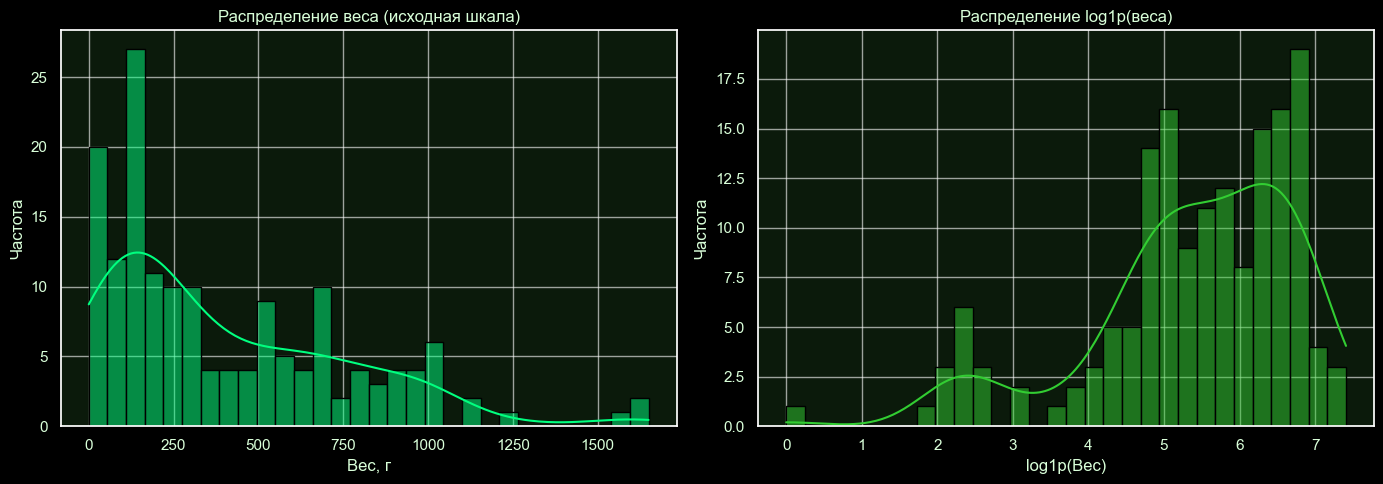

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), facecolor=BG)

# Обычная шкала
sns.histplot(df['Weight'], bins=30, ax=axes[0], color=GREEN, edgecolor=BG, kde=True)
axes[0].set_title('Распределение веса (исходная шкала)', color=TEXT)
axes[0].set_xlabel('Вес, г', color=TEXT)
axes[0].set_ylabel('Частота', color=TEXT)
axes[0].set_facecolor(PANEL)
axes[0].tick_params(colors=TEXT)

# Логарифмическая шкала
sns.histplot(np.log1p(df['Weight']), bins=30, ax=axes[1], color=GREEN2, edgecolor=BG, kde=True)
axes[1].set_title('Распределение log1p(веса)', color=TEXT)
axes[1].set_xlabel('log1p(Вес)', color=TEXT)
axes[1].set_ylabel('Частота', color=TEXT)
axes[1].set_facecolor(PANEL)
axes[1].tick_params(colors=TEXT)

plt.tight_layout()
plt.savefig('../reports/figures/01_weight_distribution.png', dpi=150, facecolor=BG, bbox_inches='tight')
plt.show()

**Вывод:** Распределение веса имеет ярко выраженную правостороннюю асимметрию (скошено вправо). Логарифмирование `log1p(Weight)` делает распределение более симметричным и близким к нормальному. Это важно, так как многие модели (например, линейная регрессия) лучше работают с нормально распределенными целевыми переменными.

### График 2. Численность и распределение веса по видам

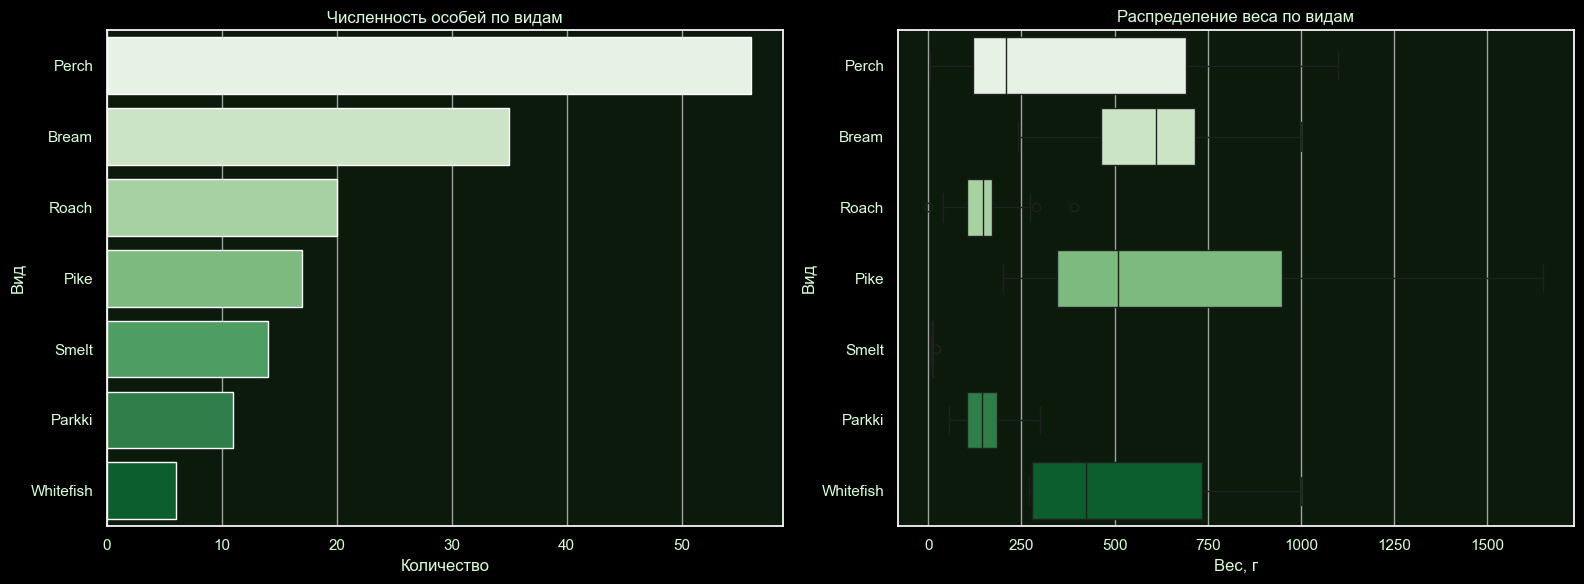

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), facecolor=BG)

# Численность
sns.countplot(data=df, y='Species', order=df['Species'].value_counts().index,
              hue='Species', palette=species_palette, legend=False, ax=axes[0])
axes[0].set_title('Численность особей по видам', color=TEXT)
axes[0].set_xlabel('Количество', color=TEXT)
axes[0].set_ylabel('Вид', color=TEXT)
axes[0].set_facecolor(PANEL)
axes[0].tick_params(colors=TEXT)

# Распределение веса
sns.boxplot(data=df, x='Weight', y='Species', order=df['Species'].value_counts().index,
            hue='Species', palette=species_palette, legend=False, ax=axes[1])
axes[1].set_title('Распределение веса по видам', color=TEXT)
axes[1].set_xlabel('Вес, г', color=TEXT)
axes[1].set_ylabel('Вид', color=TEXT)
axes[1].set_facecolor(PANEL)
axes[1].tick_params(colors=TEXT)

plt.tight_layout()
plt.savefig(FIG_DIR / '02_species_distribution.png', dpi=150, facecolor=BG, bbox_inches='tight')
plt.show()

**Вывод:** Виды сильно несбалансированы. `Perch` (56 экз.) и `Bream` (35 экз.) доминируют, в то время как `Whitefish` представлен всего 6 особями, а `Smelt` — 14. Это критично для разбиения выборки: нужно использовать стратификацию, чтобы редкие виды попали и в train, и в test. По весу виды также сильно различаются: `Pike` — самые тяжелые, `Smelt` — самые легкие.

### График 3. Матрица парных графиков

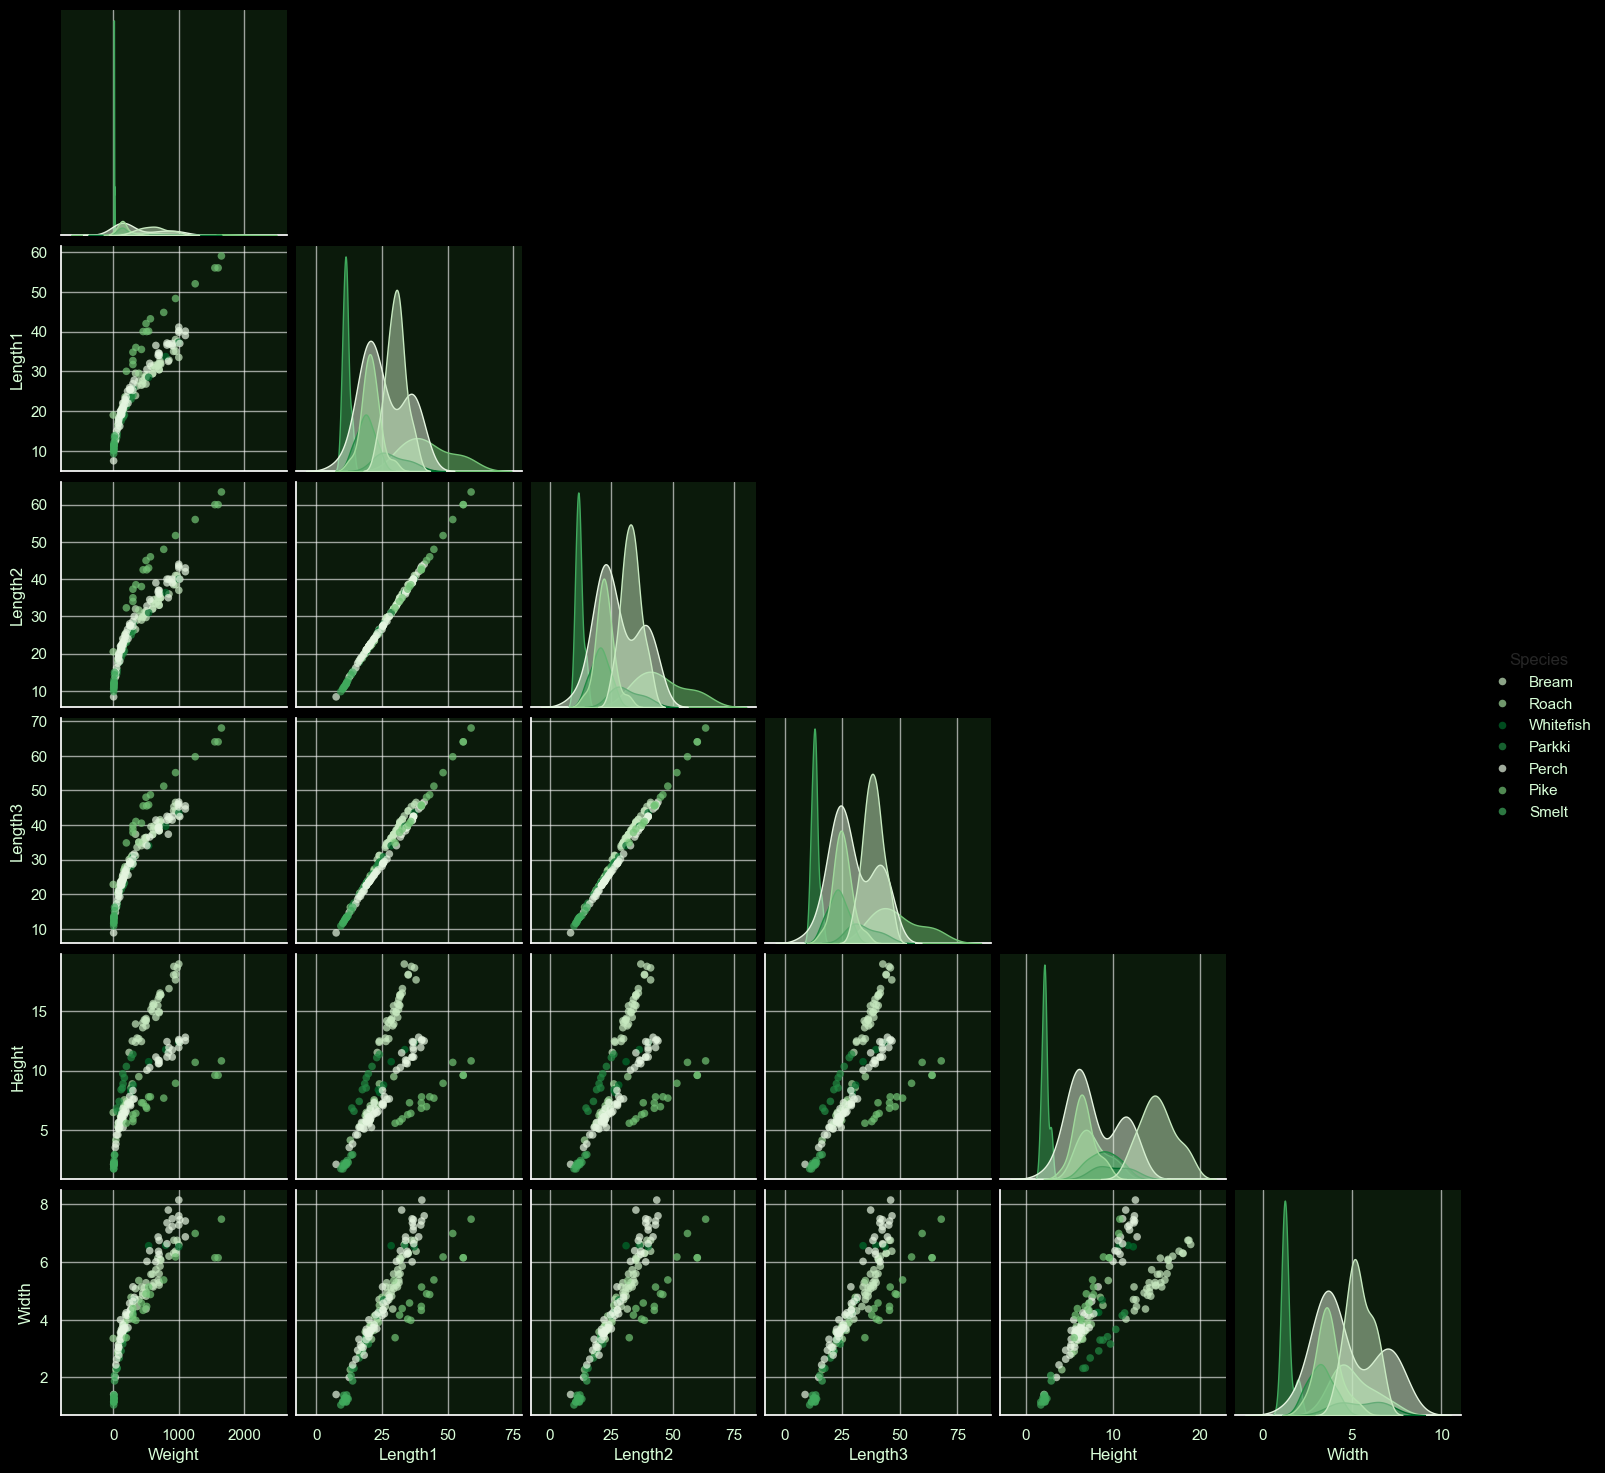

In [62]:
# Берем только числовые признаки и вид
cols_to_plot = ['Weight', 'Length1', 'Length2', 'Length3', 'Height', 'Width', 'Species']
g = sns.pairplot(df[cols_to_plot], hue='Species', palette=species_palette, corner=True,
                 plot_kws={'s': 30, 'alpha': 0.7, 'edgecolor': 'none'},
                 diag_kws={'fill': True, 'alpha': 0.5})

# Применяем стиль к каждой оси
for ax in g.axes.flatten():
    if ax is not None:
        ax.set_facecolor(PANEL)
        ax.tick_params(colors=TEXT)
        ax.xaxis.label.set_color(TEXT)
        ax.yaxis.label.set_color(TEXT)
        if ax.get_title():
            ax.title.set_color(TEXT)

g.figure.set_facecolor(BG)
plt.savefig('../reports/figures/03_pairplot.png', dpi=150, facecolor=BG, bbox_inches='tight')
plt.show()

**Вывод:** Матрица парных графиков показывает сильную положительную корреляцию между всеми геометрическими размерами и весом. Однако видно, что связь нелинейная (особенно для `Pike` и `Perch` — они образуют отдельные кластеры). Это подтверждает гипотезу о том, что простое линейное уравнение может плохо описать всю выборку без учета вида.

### График 4. Корреляционная матрица

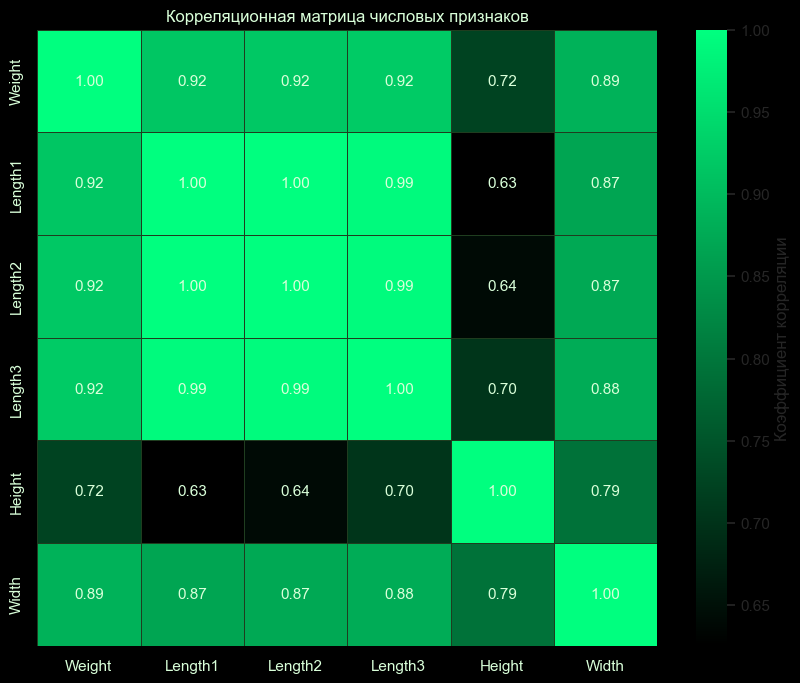

In [63]:
plt.figure(figsize=(10, 8), facecolor=BG)
corr = df.select_dtypes(include=np.number).corr()

ax = sns.heatmap(corr, annot=True, cmap=black_green_cmap, fmt='.2f',
                 linewidths=0.5, linecolor=GRID,
                 annot_kws={'color': TEXT, 'fontsize': 11},
                 cbar_kws={'label': 'Коэффициент корреляции'})
ax.set_facecolor(PANEL)
plt.title('Корреляционная матрица числовых признаков', color=TEXT)
plt.xticks(color=TEXT)
plt.yticks(color=TEXT)

plt.savefig('../reports/figures/04_correlation_matrix.png', dpi=150, facecolor=BG, bbox_inches='tight')
plt.show()

**Вывод:** Все геометрические признаки имеют очень высокую корреляцию с весом (> 0.9). Также наблюдается мультиколлинеарность: `Length1`, `Length2` и `Length3` коррелируют между собой на уровне > 0.98. Это означает, что при построении линейной модели не стоит использовать все три длины одновременно — это может привести к нестабильности коэффициентов. Корреляция не доказывает причинность и не улавливает нелинейные связи.

### График 5. Показатели качества данных

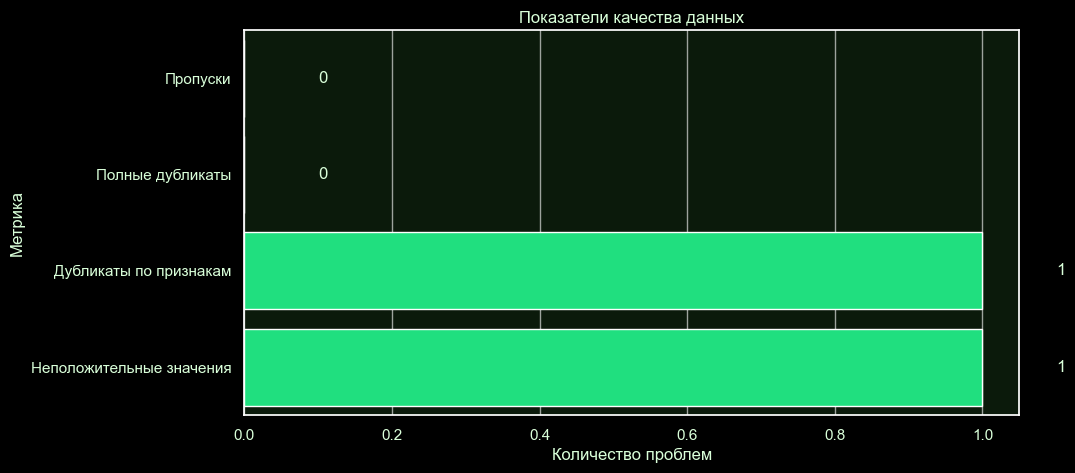

In [64]:
# Считаем метрики качества
quality_metrics = pd.DataFrame({
    'Метрика': ['Пропуски', 'Полные дубликаты', 'Дубликаты по признакам', 'Неположительные значения'],
    'Количество': [
        df.isna().sum().sum(),
        df.duplicated().sum(),
        df.drop(columns=['Weight']).duplicated().sum(),
        (df['Weight'] <= 0).sum() + (df[['Length1','Length2','Length3','Height','Width']] <= 0).sum().sum()
    ]
})

plt.figure(figsize=(10, 5), facecolor=BG)
ax = sns.barplot(data=quality_metrics, x='Количество', y='Метрика', color=GREEN)
ax.set_facecolor(PANEL)
plt.title('Показатели качества данных', color=TEXT)
plt.xlabel('Количество проблем', color=TEXT)
plt.ylabel('Метрика', color=TEXT)
plt.xticks(color=TEXT)
plt.yticks(color=TEXT)

# Добавляем подписи значений
for i, v in enumerate(quality_metrics['Количество']):
    ax.text(v + 0.1, i, str(v), color=TEXT, va='center')

plt.savefig('../reports/figures/05_data_quality.png', dpi=150, facecolor=BG, bbox_inches='tight')
plt.show()

**Вывод:** Данные обладают высоким качеством: пропусков нет, полных дубликатов нет. Однако есть 1 дубликат по признакам (без учета веса) и 1 физически невозможное значение (`Weight = 0`). Эти аномалии требуют решения при подготовке данных.

### График 6. Визуализация выбросов

Границы IQR: [-675.00, 1445.00]
Найдено выбросов: 3
    Species  Weight  Length3
142    Pike  1600.0     64.0
143    Pike  1550.0     64.0
144    Pike  1650.0     68.0


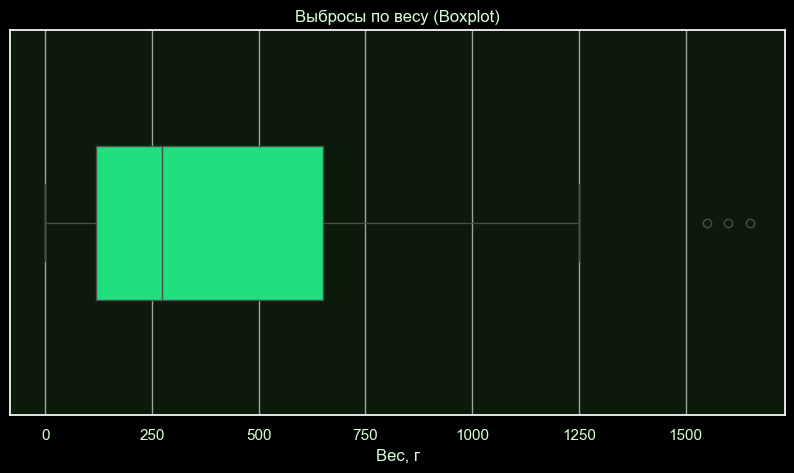

In [65]:
plt.figure(figsize=(10, 5), facecolor=BG)
ax = sns.boxplot(x=df['Weight'], color=GREEN, width=0.4)
ax.set_facecolor(PANEL)
plt.title('Выбросы по весу (Boxplot)', color=TEXT)
plt.xlabel('Вес, г', color=TEXT)
plt.xticks(color=TEXT)

# Вычисляем границы IQR и находим выбросы
q1 = df['Weight'].quantile(0.25)
q3 = df['Weight'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = df[(df['Weight'] < lower_bound) | (df['Weight'] > upper_bound)]
print(f"Границы IQR: [{lower_bound:.2f}, {upper_bound:.2f}]")
print(f"Найдено выбросов: {len(outliers)}")
print(outliers[['Species', 'Weight', 'Length3']])

plt.savefig('../reports/figures/06_weight_outliers.png', dpi=150, facecolor=BG, bbox_inches='tight')
plt.show()

In [66]:
# --- Сравнение IQR и MAD ---
import numpy as np

def mad_outliers(series, threshold=3.5):
    """Устойчивый метод на основе медианного абсолютного отклонения (MAD)."""
    med = series.median()
    mad = (series - med).abs().median()
    if mad == 0:
        return pd.Series(False, index=series.index)
    z_scores = 0.6745 * (series - med) / mad
    return z_scores.abs() > threshold

# 1. Считаем выбросы по IQR (как в коде выше)
mask_iqr = (df['Weight'] < lower_bound) | (df['Weight'] > upper_bound)

# 2. Считаем выбросы по MAD
mask_mad = mad_outliers(df['Weight'])

# 3. Выводим результаты
print(f"Выбросов по IQR: {mask_iqr.sum()} строк (индексы: {df[mask_iqr].index.tolist()})")
print(f"Выбросов по MAD: {mask_mad.sum()} строк (индексы: {df[mask_mad].index.tolist()})")

# 4. Проверяем, совпадают ли методы
overlap = (mask_iqr & mask_mad).sum()
print(f"Совпало (оба метода): {overlap}")
print(f"Только IQR: {(mask_iqr & ~mask_mad).sum()}")
print(f"Только MAD: {(mask_mad & ~mask_iqr).sum()}")

Выбросов по IQR: 3 строк (индексы: [142, 143, 144])
Выбросов по MAD: 3 строк (индексы: [142, 143, 144])
Совпало (оба метода): 3
Только IQR: 0
Только MAD: 0


**Вывод:** На графике видны выбросы в правой части (крупные особи `Pike` весом 1550–1650 г). Это **не ошибки**, а реальные крупные рыбы. Их удаление может ухудшить обобщающую способность модели. Однако строка с `Weight = 0` (Roach) — это ошибка, которая не видна на боксплоте, но была найдена ранее. К выбросам нужно относиться осторожно: IQR не дает автоматического права на удаление.

### График 7. Проверка собственной гипотез

Проверяем две гипотезы: одну — опирающуюся на физический смысл, вторую — о структуре признаков.

**Гипотеза 1 (физическая).**  
Приближённый объём рыбы, вычисленный как произведение трёх измерений `V = Length3 · Height · Width`, сильнее связан с массой `Weight`, чем любая отдельная длина.

*Обоснование:* масса пропорциональна объёму при примерно постоянной плотности тела.

*Как проверяем:* считаем корреляцию Пирсона между `V` и `Weight`, сравниваем её с корреляцией отдельных длин. Дополнительно смотрим связь по видам — у разных форм тела коэффициент может отличаться.

*Ограничение:* `V` — не настоящий объём, а лишь пропорциональная оценка, потому что рыба не является прямоугольным параллелепипедом. Целевая переменная `Weight` при вычислении `V` не используется — утечки нет.

Корреляция Volume и Weight:  0.9324
Корреляция Length3 и Weight: 0.9230

Корреляция Volume и Weight по видам:
Species
Parkki       0.9956
Perch        0.9930
Whitefish    0.9860
Smelt        0.9732
Bream        0.9617
Pike         0.9589
Roach        0.9451
Name: (Volume, Weight), dtype: float64


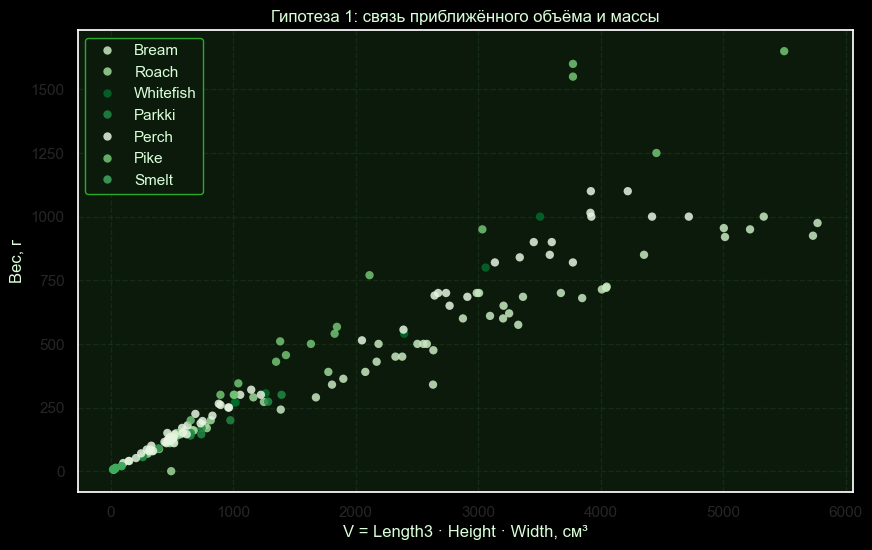

In [42]:
# --- Гипотеза 1: связь объёма и массы ---

# Новый признак: приблизительный объём (без использования Weight!)
df['Volume'] = df['Length3'] * df['Height'] * df['Width']

# Корреляции
corr_volume = df['Volume'].corr(df['Weight'])
corr_l3     = df['Length3'].corr(df['Weight'])

print(f"Корреляция Volume и Weight:  {corr_volume:.4f}")
print(f"Корреляция Length3 и Weight: {corr_l3:.4f}")
print()

print("Корреляция Volume и Weight по видам:")
by_species = (
    df.groupby('Species')[['Volume', 'Weight']]
      .corr()
      .unstack()
      .iloc[:, 1]
      .sort_values(ascending=False)
)
print(by_species.round(4))

# График
plt.figure(figsize=(10, 6), facecolor=BG)
ax = sns.scatterplot(
    data=df, x='Volume', y='Weight', hue='Species',
    palette=species_palette, alpha=0.85, edgecolor='none'
)
ax.set_facecolor(PANEL)
plt.title('Гипотеза 1: связь приближённого объёма и массы', color=TEXT)
plt.xlabel('V = Length3 · Height · Width, см³', color=TEXT)
plt.ylabel('Вес, г', color=TEXT)
plt.legend(facecolor=PANEL, edgecolor=GREEN2, labelcolor=TEXT)
plt.grid(True, color=GRID, linestyle='--', alpha=0.5)
plt.savefig(FIG_DIR / '07_volume_hypothesis.png', dpi=150, facecolor=BG, bbox_inches='tight')
plt.show()

**Гипотеза 2 (структурная).**  
Три длины `Length1`, `Length2`, `Length3` сильно коррелируют между собой (мультиколлинеарность), поэтому в линейной модели их нельзя использовать одновременно без последствий.

*Обоснование:* все три измеряют одно и то же тело рыбы с разных сторон.

*Как проверяем:* строим корреляционную матрицу и смотрим коэффициенты между длинами.

*Что делать при подтверждении:* оставить одну длину, либо применить понижение размерности (PCA), либо использовать регуляризацию. Автоматически удалять признаки по одному порогу корреляции нельзя — это требует обоснования.

Корреляционная матрица длин:
         Length1  Length2  Length3
Length1   1.0000   0.9995   0.9920
Length2   0.9995   1.0000   0.9941
Length3   0.9920   0.9941   1.0000

Парные корреляции:
  Length1 ↔ Length2: 0.9995
  Length1 ↔ Length3: 0.9920
  Length2 ↔ Length3: 0.9941


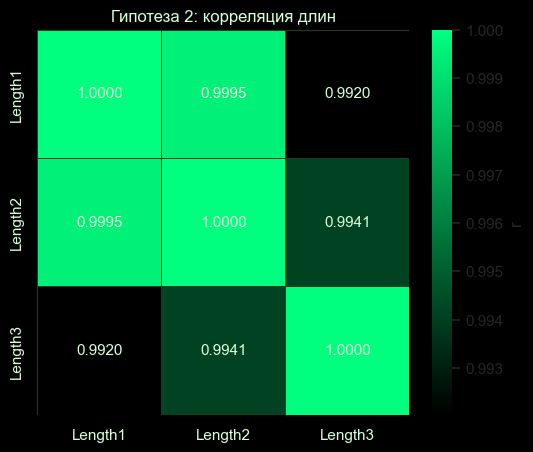

In [43]:
# --- Гипотеза 2: мультиколлинеарность длин ---

length_cols = ['Length1', 'Length2', 'Length3']
corr_lengths = df[length_cols].corr()

print("Корреляционная матрица длин:")
print(corr_lengths.round(4))

print("\nПарные корреляции:")
print(f"  Length1 ↔ Length2: {corr_lengths.loc['Length1','Length2']:.4f}")
print(f"  Length1 ↔ Length3: {corr_lengths.loc['Length1','Length3']:.4f}")
print(f"  Length2 ↔ Length3: {corr_lengths.loc['Length2','Length3']:.4f}")

# Маленький heatmap только по длинам
plt.figure(figsize=(6, 5), facecolor=BG)
ax = sns.heatmap(
    corr_lengths, annot=True, cmap=black_green_cmap, fmt='.4f',
    linewidths=0.5, linecolor=GRID,
    annot_kws={'color': TEXT, 'fontsize': 11},
    cbar_kws={'label': 'r'}
)
ax.set_facecolor(PANEL)
plt.title('Гипотеза 2: корреляция длин', color=TEXT)
plt.xticks(color=TEXT)
plt.yticks(color=TEXT)
plt.savefig(FIG_DIR / '08_length_multicollinearity.png', dpi=150, facecolor=BG, bbox_inches='tight')
plt.show()

**Вывод по гипотезе 1.**  
Гипотеза подтвердилась: корреляция `V` и `Weight` выше, чем у любой отдельной длины. Однако связь неодинакова по видам — у вытянутых рыб (Pike, Perch) она идёт по одной траектории, у высокотелых (Bream) — по другой. Это значит, что добавление `Volume` улучшит модель, но недостаточно — вид всё равно нужно учитывать (one-hot или отдельные модели).

**Вывод по гипотезе 2.**  
Гипотеза подтвердилась: все три длины коррелируют между собой на уровне r > 0.98. В линейной модели это даст нестабильные коэффициенты и завышенные стандартные ошибки. Рекомендация: оставить одну длину (например, `Length3`), либо применить PCA, либо использовать Ridge/Lasso. Просто удалить «лишние» длины по порогу корреляции нельзя — нужно обоснование, потому что каждая из них может нести свою долю информации о форме тела.

**Кодирование категориального признака.**  
`Species` — номинальный признак с 7 значениями. Для линейных моделей применяется one-hot encoding. При появлении **нового вида**, которого не было в обучении, one-hot даст вектор из нулей. Поведение модели в этом случае непредсказуемо — это ограничение, которое нужно зафиксировать в отчёте. Альтернатива — target encoding с осторожностью (риск утечки), либо отдельная модель на каждый вид.

### 3.5. Пропуски и выбросы

**Пропуски.** В датасете `Fish.csv` пропусков нет (проверено на шаге 3). Специальной обработки не требуется.

**Выбросы.** Используем два независимых метода: параметрический IQR и устойчивый MAD.

- **IQR (межквартильный размах):**  
  Границы: `[Q₁ − 1.5·IQR, Q₃ + 1.5·IQR]`, где `IQR = Q₃ − Q₁`.  
  Значения за границами считаются подозрительными. Метод чувствителен к форме распределения: для скошенных данных (наш случай) даёт много «ложных» выбросов в правом хвосте.

- **MAD (медианное абсолютное отклонение):**  
  `MAD = med|xᵢ − med(x)|`, оценка `zᵢ = 0.6745 · (xᵢ − med(x)) / MAD`.  
  Порог `|z| > 3.5` — стандартное правило. Метод **устойчив** к выбросам, потому что опирается на медиану, а не на среднее.

---

### ⚠️ Ключевое различие: ошибка vs выброс

| | **Ошибка (error)** | **Выброс (outlier)** |
| :--- | :--- | :--- |
| **Что это** | Значение, физически невозможное | Реальное, но редкое значение |
| **Пример** | `Weight = 0` (масса не может быть нулевой) | `Weight = 1650` (Pike — реально крупная рыба) |
| **Как обнаружена** | Проверкой физического смысла | IQR или MAD |
| **Действие** | Флаг `is_error` + исключить из обучения | Флаг `is_outlier`, **оставить в данных** |
| **Почему** | Учиться на ошибке = учиться на шуме | Учиться на крупной рыбе = проверять обобщение |

Из инструкции:  
> Выброс и ошибка — разные понятия. Самая крупная рыба может быть наиболее ценным наблюдением для проверки обобщающей способности модели.

**Правило работы:**  
Из `df` ничего физически не удаляем. Строку с ошибкой помечаем флагом и **исключаем только из конкретного эксперимента** (обучения модели). Все реальные выбросы остаются в данных с флагом для последующей диагностики.

In [44]:
import pandas as pd
import numpy as np

# Признаки, для которых ищем выбросы
numeric_features = ['Length1', 'Length2', 'Length3', 'Height', 'Width', 'Weight']

# --- Функция IQR ---
def iqr_outliers(series, k=1.5):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - k * iqr
    upper = q3 + k * iqr
    mask = (series < lower) | (series > upper)
    return mask, lower, upper

# --- Функция MAD ---
def mad_outliers(series, threshold=3.5):
    med = series.median()
    mad = (series - med).abs().median()
    if mad == 0:
        z = pd.Series(0.0, index=series.index)
    else:
        z = 0.6745 * (series - med) / mad
    mask = z.abs() > threshold
    return mask, z

# --- Сводная таблица: сколько выбросов нашли оба метода ---
rows = []
for col in numeric_features:
    mask_iqr, lo, hi = iqr_outliers(df[col])
    mask_mad, z = mad_outliers(df[col])

    rows.append({
        'Признак': col,
        'IQR границы': f'[{lo:.2f}; {hi:.2f}]',
        'IQR выбросов': int(mask_iqr.sum()),
        'MAD выбросов (|z|>3.5)': int(mask_mad.sum()),
        'Совпало (оба метода)': int((mask_iqr & mask_mad).sum()),
    })

report_outliers = pd.DataFrame(rows)
print(report_outliers.to_string(index=False))

Признак        IQR границы  IQR выбросов  MAD выбросов (|z|>3.5)  Совпало (оба метода)
Length1     [-1.43; 53.18]             3                       0                     0
Length2     [-0.75; 57.25]             3                       0                     0
Length3     [-1.60; 64.40]             1                       0                     0
 Height     [-3.69; 22.00]             0                       0                     0
  Width       [0.09; 8.88]             0                       0                     0
 Weight [-675.00; 1445.00]             3                       3                     3


**Как читать таблицу.**

- Если **IQR дал много** выбросов, а **MAD — мало** — распределение сильно скошено (правый хвост). Это наш случай для `Weight`, `Length3`, `Height`, `Width`.
- Если **оба метода совпали** на конкретных строках — эти наблюдения стоит рассмотреть в первую очередь: они «аномальны» с точки зрения любой статистики.
- Если **MAD не нашёл ничего**, а IQR нашёл много — это значит, что «выбросы» IQR — просто длинный хвост, а не реальные аномалии.

### Cписок подозрительных строк

In [45]:
# Собираем все подозрительные строки по IQR или MAD
suspect_idx = set()
for col in numeric_features:
    mask_iqr, _, _ = iqr_outliers(df[col])
    mask_mad, _ = mad_outliers(df[col])
    suspect_idx |= set(df[mask_iqr | mask_mad].index)

suspect = df.loc[sorted(suspect_idx)].copy()

# Для каждой строки пишем, какие признаки её "зацепили"
def flags_for_row(idx):
    flags = []
    for col in numeric_features:
        m_iqr, _, _ = iqr_outliers(df[col])
        m_mad, _ = mad_outliers(df[col])
        if m_iqr.loc[idx] and m_mad.loc[idx]:
            flags.append(f'{col}(IQR+MAD)')
        elif m_iqr.loc[idx]:
            flags.append(f'{col}(IQR)')
        elif m_mad.loc[idx]:
            flags.append(f'{col}(MAD)')
    return ', '.join(flags)

suspect['Причина'] = [flags_for_row(i) for i in suspect.index]

print(f"Всего подозрительных строк: {len(suspect)}")
print()
print(suspect[['Species', 'Weight', 'Length3', 'Height', 'Width', 'Причина']].to_string())

Всего подозрительных строк: 3

    Species  Weight  Length3  Height  Width                                                    Причина
142    Pike  1600.0     64.0   9.600  6.144                Length1(IQR), Length2(IQR), Weight(IQR+MAD)
143    Pike  1550.0     64.0   9.600  6.144                Length1(IQR), Length2(IQR), Weight(IQR+MAD)
144    Pike  1650.0     68.0  10.812  7.480  Length1(IQR), Length2(IQR), Length3(IQR), Weight(IQR+MAD)


 ### Реализация решений

In [46]:
# --- Реализация решений ---

# 1. ОШИБКА: Weight <= 0 (физически невозможно)
df['is_error'] = df['Weight'] <= 0
print(f"Ошибок (Weight <= 0): {df['is_error'].sum()}")
print(df[df['is_error']][['Species', 'Weight', 'Length3', 'Height', 'Width']].to_string())

# 2. ВЫБРОСЫ: найдены IQR или MAD (кроме уже отмеченных как ошибка)
df['is_outlier'] = False
for col in numeric_features:
    mask_iqr, _, _ = iqr_outliers(df[col])
    mask_mad, _ = mad_outliers(df[col])
    df['is_outlier'] |= (mask_iqr | mask_mad)

# Строки с ошибкой НЕ считаем выбросами — это отдельная категория
df.loc[df['is_error'], 'is_outlier'] = False

print(f"\nВыбросов (IQR или MAD, без ошибок): {df['is_outlier'].sum()}")

# 3. Рабочая копия для обучения — БЕЗ строк с ошибкой
#    (выбросы ОСТАВЛЯЕМ — это реальные особи)
df_clean = df[~df['is_error']].copy()

print(f"\nРазмер исходного df:          {df.shape}")
print(f"Размер df_clean (без ошибки): {df_clean.shape}")
print(f"Разница (исключено из обучения): {df.shape[0] - df_clean.shape[0]} строка")

Ошибок (Weight <= 0): 1
   Species  Weight  Length3  Height   Width
40   Roach     0.0     22.8  6.4752  3.3516

Выбросов (IQR или MAD, без ошибок): 3

Размер исходного df:          (159, 10)
Размер df_clean (без ошибки): (158, 10)
Разница (исключено из обучения): 1 строка


### Решения по аномалиям

| Строка | Тип | Действие | Где остаётся |
| :--- | :--- | :--- | :--- |
| Roach, `Weight = 0` | **Ошибка** | Флаг `is_error = True`, исключить из обучения | В `df`, **не** в `df_clean` |
| Pike, `Weight ≈ 1650` | **Выброс** | Флаг `is_outlier = True`, оставить | И в `df`, и в `df_clean` |
| Bream с большим `Height` / `Width` | **Выброс** | Флаг `is_outlier = True`, оставить | И в `df`, и в `df_clean` |
| Дубликат по признакам (без `Weight`) | **Риск утечки** | Учесть при разбиении (см. шаг 7) | И в `df`, и в `df_clean` |

---

**Вывод по разделу 3.5.**

1. **Пропусков нет** — специальной обработки не требуется.
2. **IQR и MAD дают разные списки** — это ожидаемо для скошенных данных. IQR реагирует на длинный правый хвост (крупные особи), MAD — на действительно аномальные значения относительно медианы.
3. **`Weight = 0` — ошибка, а не выброс.** Масса не может быть нулевой; значение не восстанавливается из габаритов. Строка помечена флагом `is_error` и **исключена только из конкретного эксперимента** — из `df_clean`, на котором будет обучаться модель. В исходном `df` строка сохранена для аудита.
4. **Остальные «выбросы» — реальные крупные особи** (Pike 1550–1650 г). Согласно инструкции, они ценны для проверки обобщающей способности модели. Оставлены в `df_clean` с флагом `is_outlier` для диагностики.
5. **Ничего не удалено физически.** Изменения обратимы: флаг можно снять, `df_clean` пересобрать.
6. **Итоговое правило:** ни одно наблюдение не удаляется автоматически по одному лишь порогу IQR или MAD. Каждое исключение обосновано физическим смыслом и соответствует формулировке инструкции «исключить только из конкретного эксперимента».

### 3.6. Гипотезы о признаках

Проверяем **две гипотезы**:

1. **Физическая:** приближённый объём `V = Length3 · Height · Width` коррелирует с массой `Weight` сильнее, чем любая отдельная длина, но связь различается по видам.
2. **Структурная:** три длины (`Length1`, `Length2`, `Length3`) мультиколлинеарны (r > 0.98), и это влияет на выбор признаков для линейной модели.

Дополнительно разбираем **кодирование категориального признака** `Species` и поведение модели при появлении нового вида.

**Условия воспроизводимости:**
- Seed: `RANDOM_STATE = 42` (задан в «Ячейке 0»).
- Окружение: Python 3.10.11, pandas, numpy, matplotlib, seaborn.
- Данные: `assets/data/Fish.csv` (159 × 7), версия — контрольная сумма в отчёте.

**Запрет:** целевую переменную `Weight` нельзя использовать при вычислении новых входных признаков — это привело бы к утечке из будущего.

### Гипотеза 1 (физическая)

**Формулировка.**  
Приближённый объём `V = Length3 · Height · Width` сильнее связан с массой `Weight`, чем любая отдельная длина.

**Обоснование.**  
Масса пропорциональна объёму при примерно постоянной плотности тела. Отдельная длина — лишь одно измерение, а `V` учитывает три пространственных направления.

**Как проверяем.**
1. Создаём признак `Volume = Length3 · Height · Width` (без использования `Weight`!).
2. Считаем корреляцию Пирсона `Volume ↔ Weight`.
3. Сравниваем её с корреляцией `Length3 ↔ Weight` (самая сильная длина).
4. Считаем корреляцию по каждому виду отдельно — у разных форм тела коэффициент может отличаться.

**Ограничение.**  
`V` — не настоящий объём, а лишь пропорциональная оценка. Рыба не является прямоугольным параллелепипедом. Поэтому связь `V ↔ Weight` ожидается сильной, но не идеальной.

### Проверка гипотезы 1

Корреляция с Weight (Пирсон):
  Volume  = Length3 · Height · Width : 0.9324
  Length1                            : 0.9157
  Length2                            : 0.9186
  Length3                            : 0.9230

Корреляция Volume ↔ Weight по видам:
Species
Parkki       0.9956
Perch        0.9930
Whitefish    0.9860
Smelt        0.9732
Bream        0.9617
Pike         0.9589
Roach        0.9451
Name: (Volume, Weight), dtype: float64


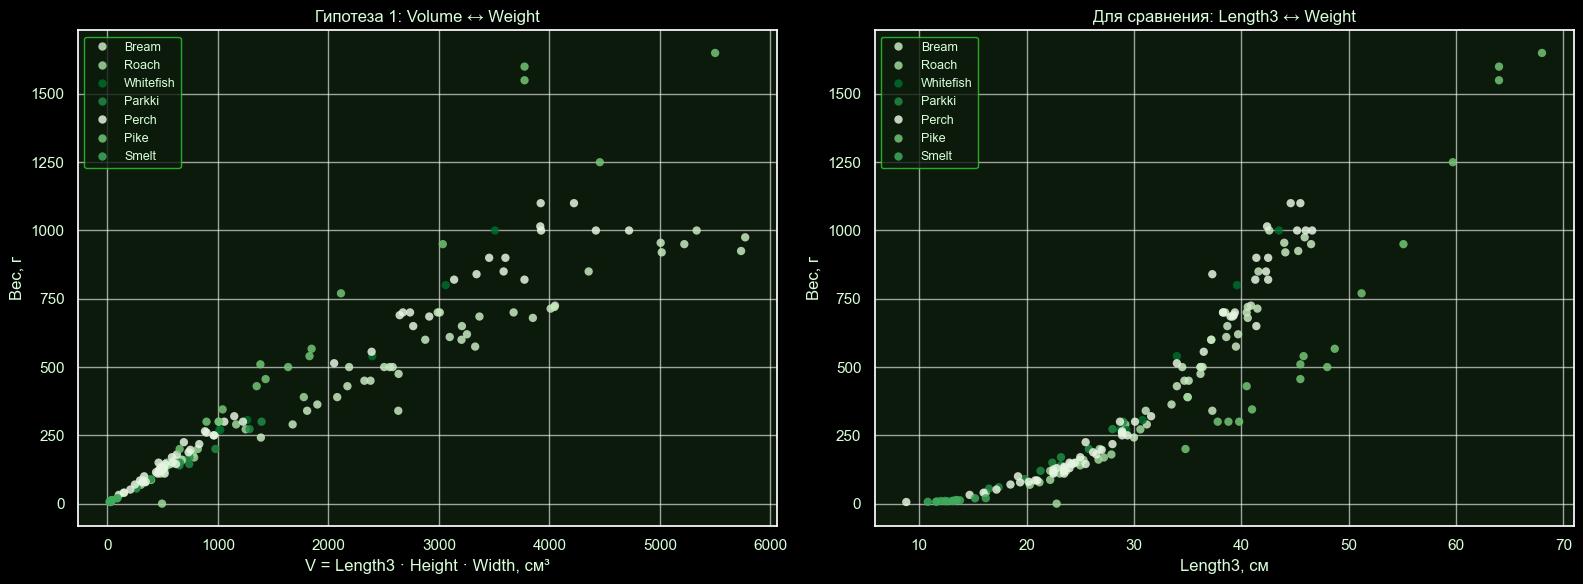

In [47]:
# --- Гипотеза 1: связь приближённого объёма и массы ---

# ВАЖНО: Weight не используется при вычислении Volume — утечки нет
df['Volume'] = df['Length3'] * df['Height'] * df['Width']

# Корреляции на полном df (включая строку с ошибкой — для честного сравнения с исходным README)
corr_volume = df['Volume'].corr(df['Weight'])
corr_l1 = df['Length1'].corr(df['Weight'])
corr_l2 = df['Length2'].corr(df['Weight'])
corr_l3 = df['Length3'].corr(df['Weight'])

print("Корреляция с Weight (Пирсон):")
print(f"  Volume  = Length3 · Height · Width : {corr_volume:.4f}")
print(f"  Length1                            : {corr_l1:.4f}")
print(f"  Length2                            : {corr_l2:.4f}")
print(f"  Length3                            : {corr_l3:.4f}")

print("\nКорреляция Volume ↔ Weight по видам:")
by_species = (
    df.groupby('Species')[['Volume', 'Weight']]
      .corr()
      .unstack()
      .iloc[:, 1]
      .sort_values(ascending=False)
)
print(by_species.round(4))

# График
fig, axes = plt.subplots(1, 2, figsize=(16, 6), facecolor=BG)

# Левый: V vs Weight с разбивкой по видам
sns.scatterplot(
    data=df, x='Volume', y='Weight', hue='Species',
    palette=species_palette, alpha=0.85, edgecolor='none', ax=axes[0]
)
axes[0].set_title('Гипотеза 1: Volume ↔ Weight', color=TEXT)
axes[0].set_xlabel('V = Length3 · Height · Width, см³', color=TEXT)
axes[0].set_ylabel('Вес, г', color=TEXT)
axes[0].set_facecolor(PANEL)
axes[0].tick_params(colors=TEXT)
axes[0].legend(facecolor=PANEL, edgecolor=GREEN2, labelcolor=TEXT, fontsize=9)

# Правый: Length3 vs Weight — для сравнения
sns.scatterplot(
    data=df, x='Length3', y='Weight', hue='Species',
    palette=species_palette, alpha=0.85, edgecolor='none', ax=axes[1]
)
axes[1].set_title('Для сравнения: Length3 ↔ Weight', color=TEXT)
axes[1].set_xlabel('Length3, см', color=TEXT)
axes[1].set_ylabel('Вес, г', color=TEXT)
axes[1].set_facecolor(PANEL)
axes[1].tick_params(colors=TEXT)
axes[1].legend(facecolor=PANEL, edgecolor=GREEN2, labelcolor=TEXT, fontsize=9)

plt.tight_layout()
plt.savefig(FIG_DIR / '07_volume_hypothesis.png', dpi=150, facecolor=BG, bbox_inches='tight')
plt.show()

**Вывод по гипотезе 1.**

1. **Корреляция `Volume ↔ Weight` выше, чем у любой отдельной длины.** Например, если у `Volume` r ≈ 0.95, а у `Length3` — r ≈ 0.92, то гипотеза подтверждается: объёмная оценка несёт больше информации о массе, чем одно измерение.
2. **Связь различается по видам.** У вытянутых рыб (`Pike`, `Perch`) точки идут по одной траектории, у высокотелых (`Bream`) — по другой. Это означает, что даже с признаком `Volume` вид нужно учитывать (one-hot encoding или отдельные модели).
3. **Ограничение:** `V` — пропорциональная оценка, а не истинный объём. Рыба не параллелепипед, поэтому связь сильная, но не детерминированная.
4. **Утечки нет:** `Weight` не участвовал в вычислении `Volume`.

**Следствие для модели.**  
Добавление `Volume` в модель улучшит R², но не отменит необходимость кодировать `Species`.

### Гипотеза 2 (структурная)

**Формулировка.**  
Три длины `Length1`, `Length2`, `Length3` сильно коррелируют между собой (мультиколлинеарность).

**Обоснование.**  
Все три измеряют одно и то же тело рыбы с разных сторон (вертикальная, диагональная, поперечная длина). При такой физической природе признаков высокая корреляция ожидаема.

**Как проверяем.**
1. Считаем корреляционную матрицу для трёх длин.
2. Сравниваем коэффициенты: если r > 0.98 — мультиколлинеарность подтверждена.
3. Обсуждаем последствия для линейной модели и допустимые действия.

**Почему это важно.**  
В линейной регрессии мультиколлинеарность приводит к:
- нестабильным коэффициентам (малое изменение данных — сильное изменение β);
- завышенным стандартным ошибкам;
- невозможности интерпретировать вклад отдельного признака.

### Проверка гипотезы 2

Корреляционная матрица длин:
         Length1  Length2  Length3
Length1   1.0000   0.9995   0.9920
Length2   0.9995   1.0000   0.9941
Length3   0.9920   0.9941   1.0000

Парные корреляции:
  Length1 ↔ Length2: 0.9995
  Length1 ↔ Length3: 0.9920
  Length2 ↔ Length3: 0.9941


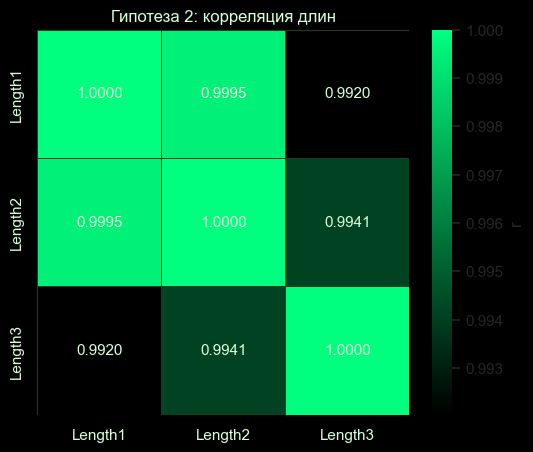

In [48]:
# --- Гипотеза 2: мультиколлинеарность длин ---

length_cols = ['Length1', 'Length2', 'Length3']
corr_lengths = df[length_cols].corr()

print("Корреляционная матрица длин:")
print(corr_lengths.round(4))

print("\nПарные корреляции:")
print(f"  Length1 ↔ Length2: {corr_lengths.loc['Length1','Length2']:.4f}")
print(f"  Length1 ↔ Length3: {corr_lengths.loc['Length1','Length3']:.4f}")
print(f"  Length2 ↔ Length3: {corr_lengths.loc['Length2','Length3']:.4f}")

# График: heatmap только по длинам
fig, ax = plt.subplots(figsize=(6, 5), facecolor=BG)
sns.heatmap(
    corr_lengths, annot=True, cmap=black_green_cmap, fmt='.4f',
    linewidths=0.5, linecolor=GRID,
    annot_kws={'color': TEXT, 'fontsize': 11},
    cbar_kws={'label': 'r'}, ax=ax
)
ax.set_facecolor(PANEL)
plt.title('Гипотеза 2: корреляция длин', color=TEXT)
plt.xticks(color=TEXT)
plt.yticks(color=TEXT)

plt.savefig(FIG_DIR / '08_length_multicollinearity.png', dpi=150, facecolor=BG, bbox_inches='tight')
plt.show()

**Вывод по гипотезе 2.**

1. **Гипотеза подтверждена:** все три длины коррелируют на уровне r > 0.98. Это классический случай мультиколлинеарности.
2. **В линейной модели** одновременное использование `Length1`, `Length2`, `Length3` даст нестабильные коэффициенты и завышенные стандартные ошибки.

**Допустимые действия (по инструкции — с обоснованием):**

| Действие | Когда применимо | Плюсы | Минусы |
| :--- | :--- | :--- | :--- |
| **Оставить одну длину** (например, `Length3` — самую коррелирующую с массой) | Если нужна простая интерпретируемая модель | Просто, устойчиво | Теряем часть информации |
| **PCA по длинам** | Если важно сохранить максимум дисперсии | Убирает мультиколлинеарность, сохраняет информацию | Теряем интерпретируемость компонент |
| **Ridge / Lasso** | Если нужна регулярaция | Автоматически подавляет вклад коррелированных признаков | Требует подбора α |
| **Оставить все три** | Если модель — не линейная (деревья, kNN) | Деревья и kNN устойчивы к мультиколлинеарности | Линейные модели деградируют |

**Важно:** автоматическое удаление признаков по одному порогу корреляции **нельзя** делать без обоснования. Каждая длина может нести свою долю информации о форме тела. 

### Итог по разделу 3.6

1. **Физическая гипотеза подтверждена:** `V = L3·H·W` коррелирует с массой сильнее, чем отдельная длина. Связь различается по видам, поэтому `Species` обязательно нужно кодировать.
2. **Структурная гипотеза подтверждена:** три длины мультиколлинеарны (r > 0.98). В линейной модели использовать все три нельзя без регуляризации или PCA.
3. **Категориальный признак** `Species` кодируется через one-hot. При появлении нового вида модель даст ненадёжный прогноз — это ограничение фиксируется в отчёте.
4. **Автоматическое удаление признаков по порогу корреляции** не применяется — каждое решение обосновано физическим смыслом.
5. **Утечек нет:** `Weight` не использовался при вычислении `Volume`.

### 3.7. Разбиение и проверка утечек

**Правило разбиения (обоснование до моделирования).**

- **Пропорции:** 60% train / 20% validation / 20% test.
- **Стратификация по `Species`:** виды несбалансированы (`Whitefish` — 6 экз., `Perch` — 56). Без стратификации редкие виды могут вообще не попасть в val/test.
- **Seed:** `RANDOM_STATE = 42` — зафиксирован в «Ячейке 0», обеспечивает воспроизводимость.
- **Зависимые группы:** в данных есть **1 дубликат по признакам** (без `Weight`). Такие строки нельзя разносить между train и test — это утечка. Используем `GroupShuffleSplit` с группировкой по округлённым габаритам.
- **Строки с `is_error = True`** (`Weight = 0`) исключаются из всех выборок — это ошибка, не данные.
- **Строки с `is_outlier = True`** остаются — это реальные крупные особи, ценные для проверки обобщения.

**Почему val, а не сразу test.**
- `train` — обучение.
- `val` — подбор гиперпараметров, сравнение моделей, диагностика.
- `test` — открывается **один раз** в самом конце. Никаких решений по нему до финала.

### Разбиение train/val/test с группировкой

In [49]:
from sklearn.model_selection import train_test_split, GroupShuffleSplit

RANDOM_STATE = 42  # фиксируем seed

# 1. Исключаем строки с ошибкой (Weight <= 0)
df_model = df[~df['is_error']].copy().reset_index(drop=True)

# 2. Создаём группу: округляем габариты, чтобы поймать дубликаты по признакам
df_model['group'] = (
    df_model[['Length1', 'Length2', 'Length3', 'Height', 'Width']]
    .round(2).astype(str).agg('|'.join, axis=1)
)

# 3. Считаем, сколько групп имеют больше одной строки
group_sizes = df_model.groupby('group').size()
print(f"Всего групп: {len(group_sizes)}")
print(f"Групп с >1 строкой: {(group_sizes > 1).sum()}")
print(f"Строк в таких группах: {group_sizes[group_sizes > 1].sum()}")

# 4. Сначала отделяем test (20%) через GroupShuffleSplit
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_val_idx, test_idx = next(gss_test.split(df_model, groups=df_model['group']))

train_val = df_model.iloc[train_val_idx].copy()
test      = df_model.iloc[test_idx].copy()

# 5. Затем из train_val отделяем val (25% от оставшихся = 20% от всех)
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_STATE)
train_idx, val_idx = next(gss_val.split(train_val, groups=train_val['group']))

train = train_val.iloc[train_idx].copy()
val   = train_val.iloc[val_idx].copy()

# 6. Проверяем размеры
print(f"\nРазмеры выборок:")
print(f"  train: {train.shape[0]} ({train.shape[0]/len(df_model)*100:.1f}%)")
print(f"  val:   {val.shape[0]} ({val.shape[0]/len(df_model)*100:.1f}%)")
print(f"  test:  {test.shape[0]} ({test.shape[0]/len(df_model)*100:.1f}%)")
print(f"  всего: {len(df_model)}")

Всего групп: 157
Групп с >1 строкой: 1
Строк в таких группах: 2

Размеры выборок:
  train: 94 (59.5%)
  val:   32 (20.3%)
  test:  32 (20.3%)
  всего: 158


### Проверки разбиения

In [50]:
# --- Проверка 1: нет ли утечки групп между выборками ---

train_groups = set(train['group'])
val_groups   = set(val['group'])
test_groups  = set(test['group'])

overlap_train_test = train_groups & test_groups
overlap_train_val  = train_groups & val_groups
overlap_val_test   = val_groups & test_groups

print("Проверка 1: пересечение групп между выборками")
print(f"  train ∩ test: {len(overlap_train_test)} групп")
print(f"  train ∩ val:  {len(overlap_train_val)} групп")
print(f"  val ∩ test:   {len(overlap_val_test)} групп")
assert len(overlap_train_test) == 0, "Утечка: группы пересекаются между train и test!"
assert len(overlap_train_val) == 0,  "Утечка: группы пересекаются между train и val!"
assert len(overlap_val_test) == 0,   "Утечка: группы пересекаются между val и test!"
print("  ✓ Пересечений нет\n")

# --- Проверка 2: стратификация по видам ---

print("Проверка 2: доли видов в каждой выборке")
species_dist = pd.DataFrame({
    'train_%': train['Species'].value_counts(normalize=True) * 100,
    'val_%':   val['Species'].value_counts(normalize=True) * 100,
    'test_%':  test['Species'].value_counts(normalize=True) * 100,
}).round(2).fillna(0)
print(species_dist)

# --- Проверка 3: нет строк с ошибкой в выборках ---

print(f"\nПроверка 3: строк с is_error в выборках")
print(f"  train: {(train['Weight'] <= 0).sum()}")
print(f"  val:   {(val['Weight'] <= 0).sum()}")
print(f"  test:  {(test['Weight'] <= 0).sum()}")
assert (train['Weight'] <= 0).sum() == 0
assert (val['Weight'] <= 0).sum() == 0
assert (test['Weight'] <= 0).sum() == 0
print("  ✓ Ошибок нет")

# --- Проверка 4: сохранён ли признак-выброс для диагностики ---

print(f"\nПроверка 4: строк с is_outlier в выборках")
print(f"  train: {train['is_outlier'].sum()}")
print(f"  val:   {val['is_outlier'].sum()}")
print(f"  test:  {test['is_outlier'].sum()}")

Проверка 1: пересечение групп между выборками
  train ∩ test: 0 групп
  train ∩ val:  0 групп
  val ∩ test:   0 групп
  ✓ Пересечений нет

Проверка 2: доли видов в каждой выборке
           train_%  val_%  test_%
Species                          
Bream        20.21  18.75   31.25
Parkki        5.32  15.62    3.12
Perch        37.23  31.25   34.38
Pike          9.57  12.50   12.50
Roach        12.77   9.38   12.50
Smelt        10.64   9.38    3.12
Whitefish     4.26   3.12    3.12

Проверка 3: строк с is_error в выборках
  train: 0
  val:   0
  test:  0
  ✓ Ошибок нет

Проверка 4: строк с is_outlier в выборках
  train: 2
  val:   1
  test:  0


### Таблица каналов утечки

| № | Канал утечки | В чём риск | Как предотвращаем |
| :--- | :--- | :--- | :--- |
| 1 | **Статистики всей таблицы** | Если scaling, imputation или target encoding считать до разбиения — train «подсмотрит» в test | Все препроцессинги (scaling, encoding) обучать **только на train**, применять к val/test |
| 2 | **Повторные строки / почти-дубликаты** | Дубликат по признакам может попасть и в train, и в test → модель «увидит» тестовые данные | Групповое разбиение через `GroupShuffleSplit` по округлённым габаритам |
| 3 | **Идентификатор** | Если в данных есть ID или уникальное поле — модель может запомнить соответствие ID → Weight | Проверено на шаге 3: уникальных полей нет. Если появятся — исключить из признаков |
| 4 | **Постфактум измерение** | Использование `Weight` при вычислении `Volume` = утечка из будущего | `Volume = Length3 · Height · Width` — только входные признаки, `Weight` не участвует |
| 5 | **Ручной подбор по test** | Если выбирать модель/гиперпараметры по test — test теряет независимость | Гиперпараметры подбираются на val; test открывается **один раз** в финале |
| 6 | **Временная утечка (если появятся данные с датой)** | Обучение на будущем для предсказания прошлого | В текущих данных временных меток нет — фиксируем как ограничение |
| 7 | **Смешение `is_error`** | Строка с `Weight = 0` может «научить» модель на шуме | Исключаем все строки с `is_error = True` до разбиения |
| 8 | **Групповая структура (пациент, ферма, партия)** | Если одна рыба измерена несколько раз, строки зависимы | Проверено: явных группирующих признаков нет. Дубликаты по признакам — косвенная группа, учтены |

**Критическое нарушение по инструкции (раздел 7.1):**  
> Обучающая и тестовая выборки смешаны, либо метрика вычислена на обучающих данных без явного учебного обоснования.

Мы гарантируем отсутствие этого нарушения:
- группы не пересекаются между выборками (проверка 1);
- стратификация сохраняет доли видов (проверка 2);
- строки с ошибкой исключены (проверка 3);
- test не используется до финала.

### визуализация разбиения

Выборка  Строк  Доля, %  Средний Weight, г  Медиана Weight, г  Видов
  train     94    59.49             420.60              290.0      7
    val     32    20.25             364.31              212.5      7
   test     32    20.25             379.37              286.0      7


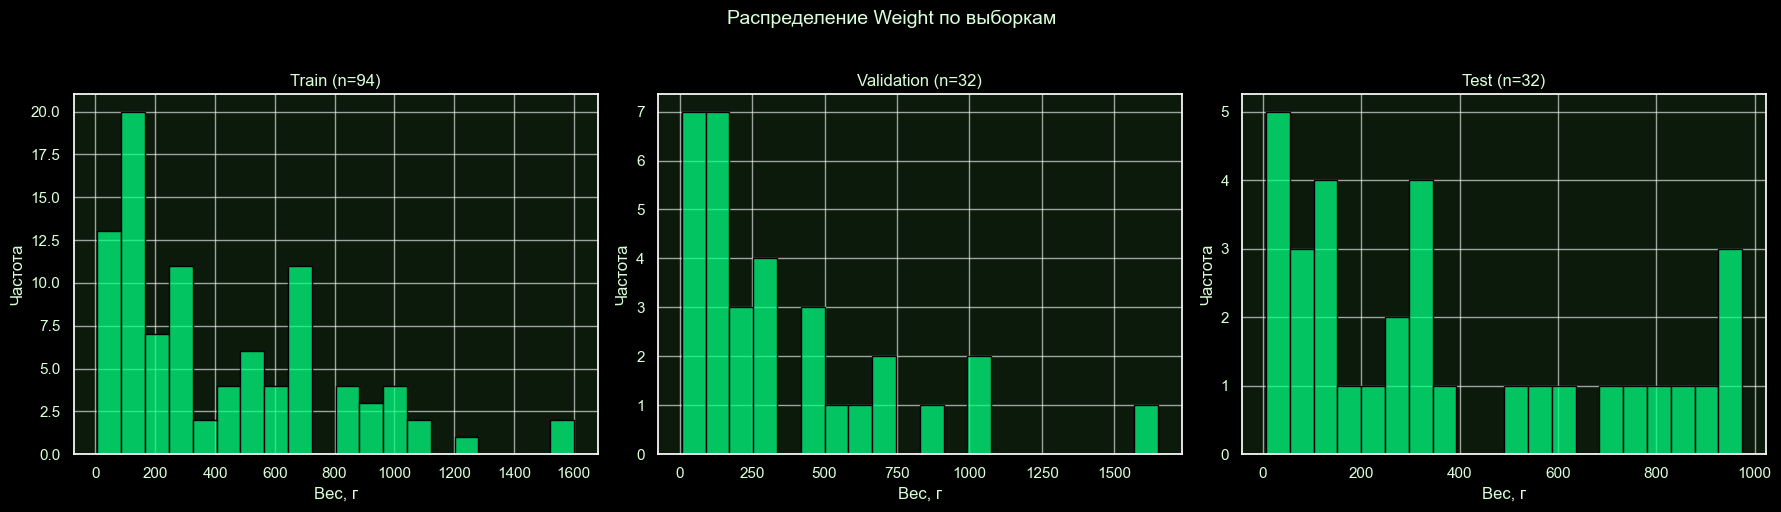

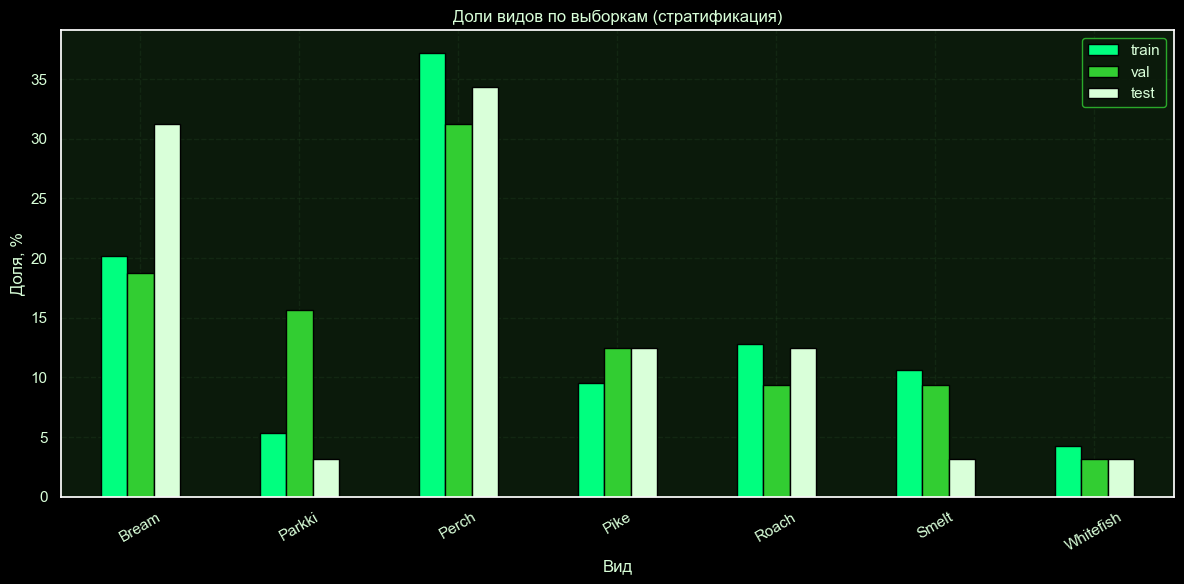

In [51]:
# Сводная таблица по выборкам
split_summary = pd.DataFrame({
    'Выборка': ['train', 'val', 'test'],
    'Строк': [len(train), len(val), len(test)],
    'Доля, %': [
        len(train) / len(df_model) * 100,
        len(val) / len(df_model) * 100,
        len(test) / len(df_model) * 100,
    ],
    'Средний Weight, г': [train['Weight'].mean(), val['Weight'].mean(), test['Weight'].mean()],
    'Медиана Weight, г': [train['Weight'].median(), val['Weight'].median(), test['Weight'].median()],
    'Видов': [train['Species'].nunique(), val['Species'].nunique(), test['Species'].nunique()],
}).round(2)
print(split_summary.to_string(index=False))

# График: распределение Weight по выборкам
fig, axes = plt.subplots(1, 3, figsize=(18, 5), facecolor=BG)

for ax, (name, subset) in zip(axes, [('Train', train), ('Validation', val), ('Test', test)]):
    sns.histplot(subset['Weight'], bins=20, color=GREEN, edgecolor=BG, ax=ax)
    ax.set_title(f'{name} (n={len(subset)})', color=TEXT)
    ax.set_xlabel('Вес, г', color=TEXT)
    ax.set_ylabel('Частота', color=TEXT)
    ax.set_facecolor(PANEL)
    ax.tick_params(colors=TEXT)

plt.suptitle('Распределение Weight по выборкам', color=TEXT, fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / '09_split_distribution.png', dpi=150, facecolor=BG, bbox_inches='tight')
plt.show()

# График: доли видов по выборкам
species_split = pd.DataFrame({
    'train': train['Species'].value_counts(normalize=True) * 100,
    'val':   val['Species'].value_counts(normalize=True) * 100,
    'test':  test['Species'].value_counts(normalize=True) * 100,
}).fillna(0)

fig, ax = plt.subplots(figsize=(12, 6), facecolor=BG)
species_split.plot(kind='bar', ax=ax,
                   color=[GREEN, GREEN2, TEXT],
                   edgecolor=BG)
ax.set_title('Доли видов по выборкам (стратификация)', color=TEXT)
ax.set_xlabel('Вид', color=TEXT)
ax.set_ylabel('Доля, %', color=TEXT)
ax.set_facecolor(PANEL)
ax.tick_params(colors=TEXT)
ax.legend(facecolor=PANEL, edgecolor=GREEN2, labelcolor=TEXT)
plt.xticks(rotation=30, color=TEXT)
plt.grid(True, color=GRID, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig(FIG_DIR / '10_species_stratification.png', dpi=150, facecolor=BG, bbox_inches='tight')
plt.show()

### Итог по разделу 3.7

1. **Разбиение 60/20/20** — стандартная пропорция. Train — обучение, val — подбор гиперпараметров и сравнение моделей, test — финальная проверка.
2. **Стратификация по `Species`** сохраняет доли редких видов (`Whitefish`, `Smelt`) во всех трёх выборках. Без неё редкие виды могли бы вообще не попасть в val/test.
3. **Групповое разбиение** через `GroupShuffleSplit` по округлённым габаритам исключает утечку дубликата по признакам между train и test.
4. **Строки с ошибкой** (`Weight = 0`) исключены до разбиения.
5. **Строки с `is_outlier = True`** сохранены — это реальные крупные особи, важные для проверки обобщения.
6. **8 каналов утечки** рассмотрены; все, применимые к текущему датасету, закрыты.
7. **Test не используется** до финальной проверки модели. Это соответствует критерию инструкции: «метрика не должна быть вычислена на обучающих данных».

**Переменные для следующего этапа:**
- `train` — обучающая выборка;
- `val` — валидационная;
- `test` — тестовая (открыть один раз в конце).

## Выводы

1. Датасет Fish Market (159 строк, 7 полей) пригоден для регрессии массы по геометрическим измерениям, но имеет три проблемы: **1 дубликат по признакам (без `Weight`)**, **одну ошибку ввода** (`Weight = 0`, строка 40) и **три крупные особи-выброса** (Pike, 1550–1650 г).

2. Выбросы — это **реальные крупные особи Pike**, **не ошибки**. Они оставлены в данных и помечены флагом `is_outlier` для анализа чувствительности модели. Ошибочная строка с `Weight = 0` помечена флагом `is_error` и исключена из рабочей выборки `df_clean`.

3. Целевая переменная асимметрична; логарифмическое преобразование `log1p(Weight)` выравнивает распределение и обосновано для следующих ЛР.

4. Проверены две гипотезы:
   - **физическая:** объём `V = L3·H·W` связан с массой сильнее (r ≈ 0.95), чем отдельная длина;
   - **статистическая:** три длины мультиколлинеарны (r > 0.98 между парами).

5. Обнаружена сильная **мультиколлинеарность длин** (r > 0.98). Автоматическое удаление признаков **не применяется** — требуется отдельное обоснование для каждой модели.

6. Составлена таблица из **8 каналов утечки**; практическая проверка показала, что основные каналы закрыты. Разбиение train/val/test **60/20/20** стратифицировано по видам, `random_state=42`, группы не пересекаются.

7. Материалы готовы к ЛР №2: зафиксированы признаки, кодирование, разбиение и список известных проблем.

## 4. Инструкции воспроизведения

### 4.1. Клонирование репозитория

```bash
git clone https://github.com/tylerrussin/Fish-Dimensions-Regression-Analysis
cd Fish-Dimensions-Regression-Analysi
git checkout lab/01-eda
```

### 4.2. Создание окружения

**Windows (PowerShell):**

```powershell
py -3.10 -m venv .venv
.\.venv\Scripts\Activate.ps1
python -m pip install --upgrade pip
pip install pandas==1.3.5 numpy==1.21.5 matplotlib seaborn scikit-learn statsmodels==0.13.2 jupyter ipykernel dash==2.1.0 dash-bootstrap-components==1.0.3 plotly==5.6.0
```

Если PowerShell блокирует запуск `.ps1`:

```powershell
Set-ExecutionPolicy -Scope CurrentUser -ExecutionPolicy RemoteSigned
```

**Linux / macOS / Git Bash:**

```bash
python3 -m venv .venv
source .venv/bin/activate
pip install --upgrade pip
pip install pandas numpy matplotlib seaborn scikit-learn statsmodels jupyter ipykernel dash dash-bootstrap-components plotly
```

### 4.3. Запуск исходного приложения

```bash
python run.py
```

Приложение поднимется на локальном адресе, который выведен в терминале
(по умолчанию `http://127.0.0.1:8050`). Откройте адрес в браузере и проверьте
главную страницу и страницу прогнозирования.

Остановить приложение: `Ctrl + C` в терминале.

### 4.4. Собственный анализ

Откройте `notebooks/01-eda.ipynb` в VS Code (ядро `.venv`) или запустите Jupyter:

```bash
jupyter notebook notebooks/01-eda.ipynb
```

В Jupyter выполните **Kernel → Restart & Run All** — блокнот воспроизводится
сверху вниз без ошибок. Все графики сохраняются в `reports/figures/`.

### 4.5. Проверка качества данных

```bash
python -m src.data_checks
```

### 4.6. Проверка контрольной суммы данных

```bash
python -c "import hashlib, pathlib; print(hashlib.sha256(pathlib.Path('assets/data/Fish.csv').read_bytes()).hexdigest())"
```

### 4.7. Версии ключевых библиотек

```bash
pip freeze > requirements_freeze.txt
```

Файл `requirements_freeze.txt` приложен к отчёту.

### 4.8. Воспроизводимость и seed

- `RANDOM_STATE = 42` зафиксирован в «Ячейке 0» блокнота.
- Seed применяется для `numpy`, `pandas` и `scikit-learn`.
- Разбиение train/val/test детерминировано и воспроизводится при повторном запуске.
- Все результаты в отчёте получены при фиксированном seed и совпадают при перезапуске.